# ThoraxAI: Multi-Label Chest X-Ray Diagnostic Engine (DenseNet-121 + Grad-CAM)

End-to-end training, patient-aware validation, Explainable AI (Grad-CAM), zero-shot spatial resolution benchmarking, and interactive Gradio UI on **NIH ChestX-ray14** (112,120 images, 30,805 unique patients, 14 pathologies).

In [1]:
# 1. Install & setup Kaggle credentials
!pip install -q kaggle
from google.colab import files
files.upload() # Upload file kaggle.json kamu

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# 2. Download dataset NIH ChestX-ray14 (~42 GB)
!kaggle datasets download -d nih-chest-xrays/data

# 3. Unzip dataset
!unzip -q data.zip -d ./nih_dataset
print("Selesai diekstrak!")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
License(s): CC0-1.0
100% 42.0G/42.0G [17:39<00:00, 42.6MB/s]

Selesai diekstrak!


[CELL 2] Setup Library, GPU, & Reproducibility

Kegunaan: Mempersiapkan pustaka utama (PyTorch, Torchvision, Scikit-learn, OpenCV), mengunci random seed, dan memastikan GPU A100 kamu terdeteksi.

In [2]:
import os
import random
from glob import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score

# Deteksi GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device aktif: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

Device aktif: cuda (NVIDIA A100-SXM4-80GB)


[CELL 3] Parsing Metadata & Patient-Aware Split

Kegunaan: Memetakan lokasi gambar, melakukan one-hot encoding untuk 14 kelas penyakit, dan membagi dataset menjadi Train/Val berdasarkan Patient ID agar tidak terjadi data leakage.

In [3]:
# Cari CSV metadata
csv_candidates = glob('./nih_dataset/**/Data_Entry_2017*.csv', recursive=True)
csv_path = csv_candidates[0] if csv_candidates else './nih_dataset/Data_Entry_2017.csv'
df = pd.read_csv(csv_path)

# Petakan path file gambar
all_image_paths = {os.path.basename(p): p for p in glob('./nih_dataset/**/*.png', recursive=True)}
df['image_path'] = df['Image Index'].map(all_image_paths)
df = df.dropna(subset=['image_path']).reset_index(drop=True)

# 14 Patologi standar NIH ChestX-ray14
DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
    'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# One-hot encoding multi-label
for disease in DISEASE_LABELS:
    df[disease] = df['Finding Labels'].apply(lambda x: 1 if disease in str(x) else 0)

# Split berdasarkan Patient ID (80% Train, 20% Val)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df['Patient ID']))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print(f"Total dataset valid: {len(df)}")
print(f"Data Training: {len(train_df)} gambar ({train_df['Patient ID'].nunique()} pasien unik)")
print(f"Data Validasi: {len(val_df)} gambar ({val_df['Patient ID'].nunique()} pasien unik)")

Total dataset valid: 112120
Data Training: 89826 gambar (24644 pasien unik)
Data Validasi: 22294 gambar (6161 pasien unik)


[CELL 4] Dataset & Transformasi Augmentasi Medis

Kegunaan: Membuat pipeline transformasi data dengan augmentasi yang aman secara medis (rotasi ringan, kecerahan/kontras) serta kelas Dataset PyTorch.

In [4]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.image_paths = dataframe['image_path'].values
        self.labels = dataframe[DISEASE_LABELS].values.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, label

[CELL 5] DataLoader Dioptimasi untuk A100

Kegunaan: Menyusun antrean batch data dengan batch_size=64, num_workers=4, dan pin_memory=True untuk memaksimalkan throughput transfer data ke GPU.

In [5]:
train_dataset = ChestXrayDataset(train_df, transform=train_transforms)
val_dataset = ChestXrayDataset(val_df, transform=val_transforms)

BATCH_SIZE = 64
NUM_WORKERS = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"DataLoader siap. Jumlah batch train: {len(train_loader)}, batch val: {len(val_loader)}")

DataLoader siap. Jumlah batch train: 1404, batch val: 349


[CELL 6] Arsitektur Model (DenseNet-121 CheXNet)

Kegunaan: Mengunduh model transfer learning DenseNet-121 dan mengganti layer klasifikasi akhirnya menjadi 14 unit output.

In [6]:
def build_model(num_classes=14):
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    in_features = model.classifier.in_features
    model.classifier = nn.Linear(in_features, num_classes)
    return model

model = build_model(num_classes=len(DISEASE_LABELS)).to(device)
print("DenseNet-121 siap dengan 14 output neuron.")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 205MB/s]


DenseNet-121 siap dengan 14 output neuron.


[CELL 7] Loss Function Berbobot (Weighted BCE) & Optimizer

Kegunaan: Menangani class imbalance parah pada dataset rontgen dengan memberikan bobot positif (pos_weight) pada kelas-kelas langka.

In [7]:
pos_counts = train_df[DISEASE_LABELS].sum().values
neg_counts = len(train_df) - pos_counts
pos_weights = torch.tensor(neg_counts / (pos_counts + 1e-5), dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
epochs = 5
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

[CELL 8] Training & Validation Loop dengan AMP

Kegunaan: Melatih model dengan Automatic Mixed Precision (AMP) agar efisien pada GPU A100 dan menghitung skor rata-rata ROC-AUC di setiap epoch.

In [8]:
from torch.amp import GradScaler, autocast

scaler = GradScaler('cuda')

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for images, targets in train_loader:
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)

        optimizer.zero_grad()
        with autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    scheduler.step()

    # Validasi
    model.eval()
    val_loss = 0.0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            with autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, targets)

            val_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(outputs).cpu().numpy()
            all_preds.append(probs)
            all_targets.append(targets.cpu().numpy())

    val_loss = val_loss / len(val_loader.dataset)
    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)

    auc_scores = [roc_auc_score(all_targets[:, i], all_preds[:, i]) for i in range(len(DISEASE_LABELS))]
    print(f"Epoch [{epoch}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Mean ROC-AUC: {np.mean(auc_scores):.4f}")

torch.save(model.state_dict(), "thoraxai_model.pth")

Epoch [1/5] | Train Loss: 1.0891 | Val Loss: 1.0294 | Mean ROC-AUC: 0.7947


Epoch [2/5] | Train Loss: 0.9819 | Val Loss: 0.9918 | Mean ROC-AUC: 0.8136


Epoch [3/5] | Train Loss: 0.9100 | Val Loss: 0.9624 | Mean ROC-AUC: 0.8222


Epoch [4/5] | Train Loss: 0.8470 | Val Loss: 0.9613 | Mean ROC-AUC: 0.8301


Epoch [5/5] | Train Loss: 0.8013 | Val Loss: 0.9550 | Mean ROC-AUC: 0.8326


[CELL 9] Visualisasi 1: Citra Rontgen vs Matriks Angka

Kegunaan: Memvisualisasikan prinsip bahwa citra rontgen di mata CNN hanyalah matriks intensitas radiasi. Kotak zoom menunjukkan transisi antara rongga paru yang gelap (nilai mendekati 0) dan tulang iga yang terang (nilai mendekati 255).

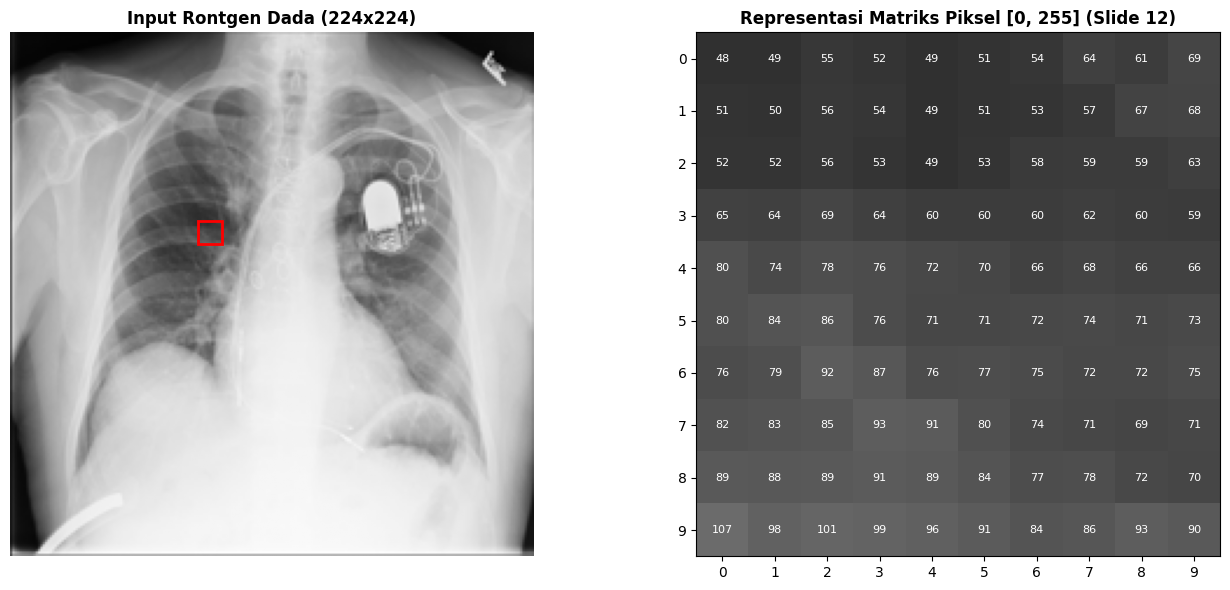

In [9]:
# Ambil 1 gambar mentah
sample_path = val_df['image_path'].iloc[0]
raw_img = Image.open(sample_path).convert('L') # Mode grayscale
raw_img_np = np.array(raw_img.resize((224, 224)))

# Area crop kecil 10x10 pada area tulang iga
x_start, y_start = 80, 80
crop_patch = raw_img_np[y_start:y_start+10, x_start:x_start+10]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Panel Kiri: Citra Rontgen dengan kotak merah
ax1.imshow(raw_img_np, cmap='gray')
rect = plt.Rectangle((x_start, y_start), 10, 10, edgecolor='red', facecolor='none', linewidth=2)
ax1.add_patch(rect)
ax1.set_title("Input Rontgen Dada (224x224)", fontsize=12, fontweight='bold')
ax1.axis('off')

# Panel Kanan: Representasi Matriks Piksel [0, 255]
ax2.imshow(crop_patch, cmap='gray', vmin=0, vmax=255)
for i in range(10):
    for j in range(10):
        val = crop_patch[i, j]
        color = 'black' if val > 128 else 'white'
        ax2.text(j, i, f"{val}", ha="center", va="center", color=color, fontsize=8)

ax2.set_title("Representasi Matriks Piksel [0, 255]", fontsize=12, fontweight='bold')
ax2.set_xticks(range(10))
ax2.set_yticks(range(10))
plt.tight_layout()
plt.show()

[CELL 10] Visualisasi 2: Galeri Augmentasi Medis

Kegunaan: Menampilkan perbandingan citra sebelum dan sesudah augmentasi untuk membuktikan bahwa manipulasi posisi dan pencahayaan tetap menjaga integritas anatomi paru.

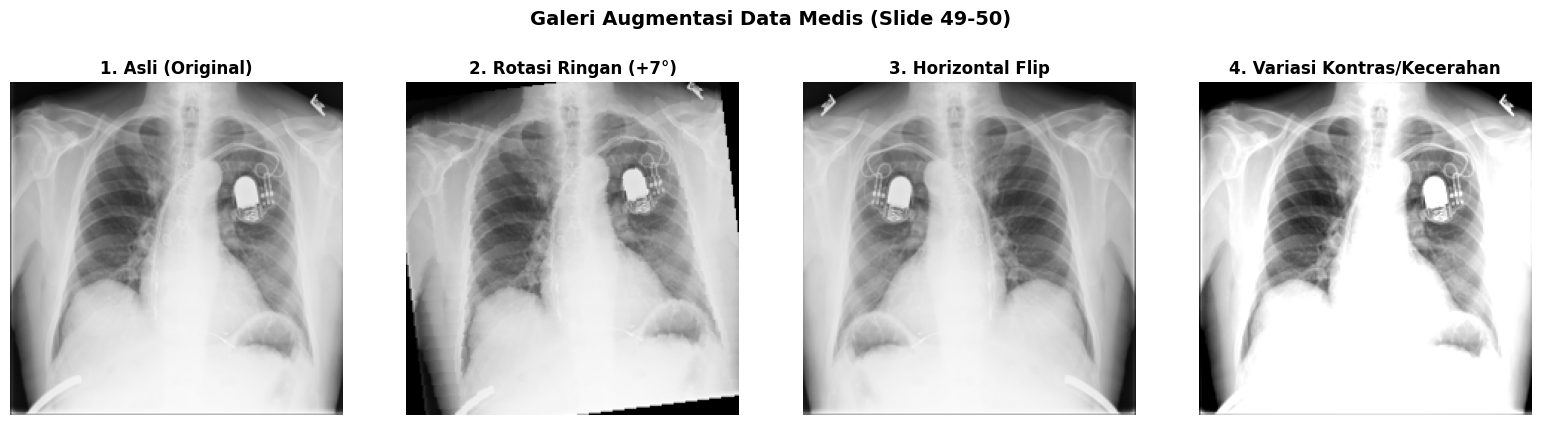

In [10]:
raw_pil = Image.open(sample_path).convert('RGB').resize((224, 224))

aug_rot = transforms.RandomRotation(degrees=(7, 7))(raw_pil)
aug_flip = transforms.RandomHorizontalFlip(p=1.0)(raw_pil)
aug_jitter = transforms.ColorJitter(brightness=0.3, contrast=0.3)(raw_pil)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(raw_pil)
axes[0].set_title("1. Asli (Original)", fontweight='bold')

axes[1].imshow(aug_rot)
axes[1].set_title("2. Rotasi Ringan (+7°)", fontweight='bold')

axes[2].imshow(aug_flip)
axes[2].set_title("3. Horizontal Flip", fontweight='bold')

axes[3].imshow(aug_jitter)
axes[3].set_title("4. Variasi Kontras/Kecerahan", fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.suptitle("Galeri Augmentasi Data Medis", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

[CELL 11] Visualisasi 3: Bobot Filter Konvolusi Layer Pertama

Kegunaan: Memvisualisasikan bobot kernel konvolusi layer conv0 (
7
×
7
7×7) untuk memperlihatkan bagaimana filter mempelajari orientasi garis, tepi tulang, dan kontur diafragma layaknya neuron biologis.

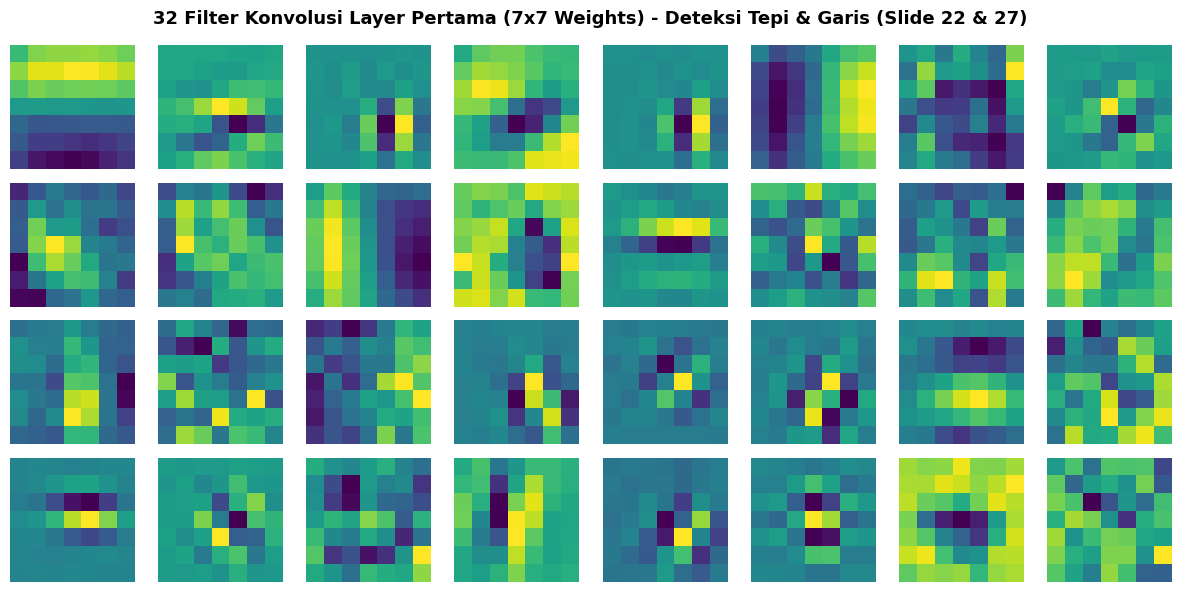

In [11]:
# Ambil bobot filter layer konvolusi pertama
weights = model.features.conv0.weight.data.cpu() # shape: (64, 3, 7, 7)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < 32:
        # Normalisasi kernel ke [0, 1] untuk divisualisasikan
        kernel = weights[i].numpy()
        kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-5)
        # Tampilkan rata-rata kanal atau kanal pertama
        ax.imshow(np.mean(kernel, axis=0), cmap='viridis')
    ax.axis('off')

plt.suptitle("32 Filter Konvolusi Layer Pertama (7x7 Weights) - Deteksi Tepi & Garis",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

[CELL 12] Visualisasi 4: Aliran Feature Map & Prediksi 14 Penyakit

Kegunaan: Menampilkan visualisasi memperlihatkan bagaimana gambar rontgen bertransformasi dari layer awal (tepi tulang), layer tengah (tekstur opasitas), layer dalam (fitur penyakit), hingga bar probabilitas multi-label di output.

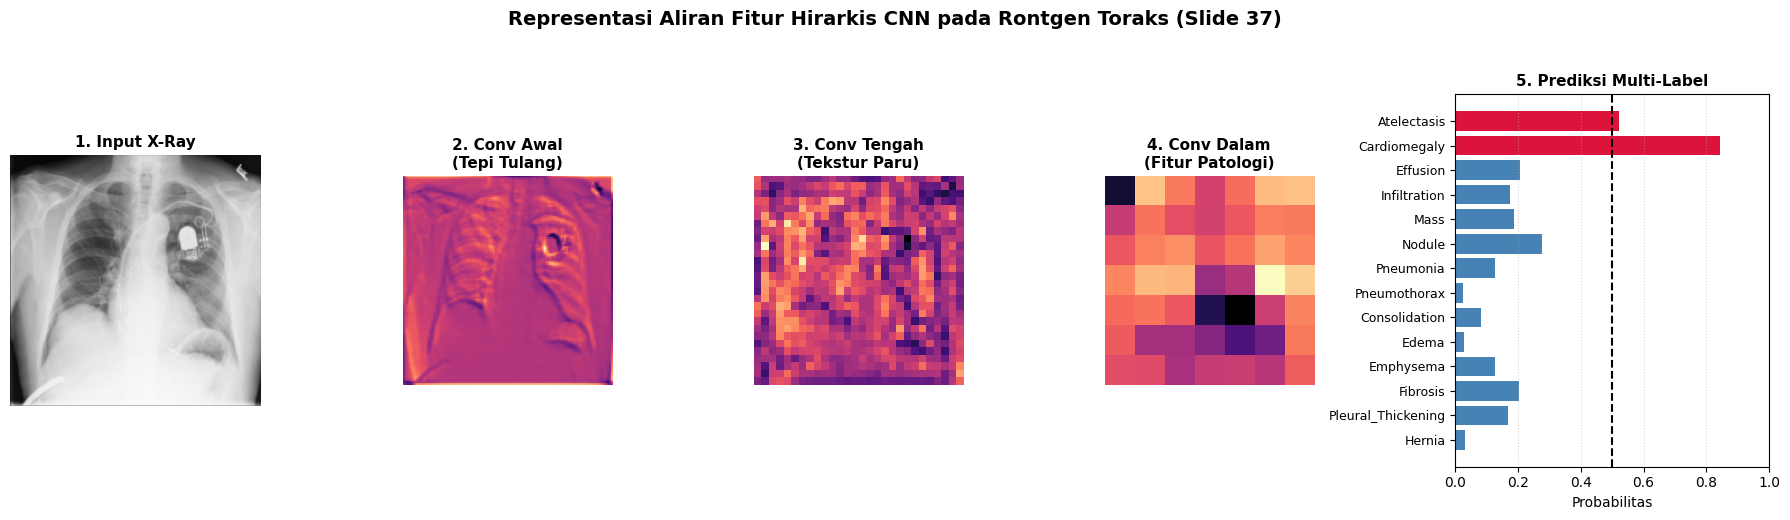

In [12]:
activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

# Hook pada DenseNet-121
hook1 = model.features.conv0.register_forward_hook(get_activation('early_conv'))
hook2 = model.features.denseblock2.register_forward_hook(get_activation('mid_conv'))
hook3 = model.features.denseblock4.register_forward_hook(get_activation('deep_conv'))

# Ambil sampel validasi
test_img_tensor, test_label = val_dataset[0]
input_tensor = test_img_tensor.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(input_tensor)
    probs = torch.sigmoid(logits).squeeze().cpu().numpy()

early_feat = activation['early_conv'].squeeze().cpu().numpy()
mid_feat = activation['mid_conv'].squeeze().cpu().numpy()
deep_feat = activation['deep_conv'].squeeze().cpu().numpy()

# Visualisasi alur end-to-end
fig = plt.figure(figsize=(18, 5))
gs = fig.add_gridspec(1, 5, width_ratios=[1.2, 1, 1, 1, 1.5])

# 1. Input
ax0 = fig.add_subplot(gs[0])
disp_img = test_img_tensor.permute(1, 2, 0).cpu().numpy()
disp_img = np.clip(disp_img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
ax0.imshow(disp_img, cmap='gray')
ax0.set_title("1. Input X-Ray", fontsize=11, fontweight='bold')
ax0.axis('off')

# 2. Conv Awal
ax1 = fig.add_subplot(gs[1])
ax1.imshow(np.mean(early_feat[:8], axis=0), cmap='magma')
ax1.set_title("2. Conv Awal\n(Tepi Tulang)", fontsize=11, fontweight='bold')
ax1.axis('off')

# 3. Conv Tengah
ax2 = fig.add_subplot(gs[2])
ax2.imshow(np.mean(mid_feat[:16], axis=0), cmap='magma')
ax2.set_title("3. Conv Tengah\n(Tekstur Paru)", fontsize=11, fontweight='bold')
ax2.axis('off')

# 4. Conv Akhir
ax3 = fig.add_subplot(gs[3])
ax3.imshow(np.mean(deep_feat[:32], axis=0), cmap='magma')
ax3.set_title("4. Conv Dalam\n(Fitur Patologi)", fontsize=11, fontweight='bold')
ax3.axis('off')

# 5. Output Probabilitas
ax4 = fig.add_subplot(gs[4])
colors = ['crimson' if p > 0.5 else 'steelblue' for p in probs]
y_pos = np.arange(len(DISEASE_LABELS))
ax4.barh(y_pos, probs, color=colors)
ax4.axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
ax4.set_yticks(y_pos)
ax4.set_yticklabels(DISEASE_LABELS, fontsize=9)
ax4.invert_yaxis()
ax4.set_xlim(0, 1.0)
ax4.set_xlabel('Probabilitas')
ax4.set_title("5. Prediksi Multi-Label", fontsize=11, fontweight='bold')
ax4.grid(axis='x', linestyle=':', alpha=0.5)

plt.suptitle("Representasi Aliran Fitur Hirarkis CNN pada Rontgen Toraks", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Hapus hook setelah dipakai
hook1.remove(); hook2.remove(); hook3.remove()

[CELL 13] Visualisasi 5: Grad-CAM Heatmap Lokalisasi

Kegunaan: Menghubungkan Task Klasifikasi ke Lokalisasi Penyakit. Grad-CAM menghasilkan peta panas (heatmap) yang menyorot bagian paru/jantung mana yang memicu model memprediksi penyakit tertentu tanpa memerlukan bounding box manual.

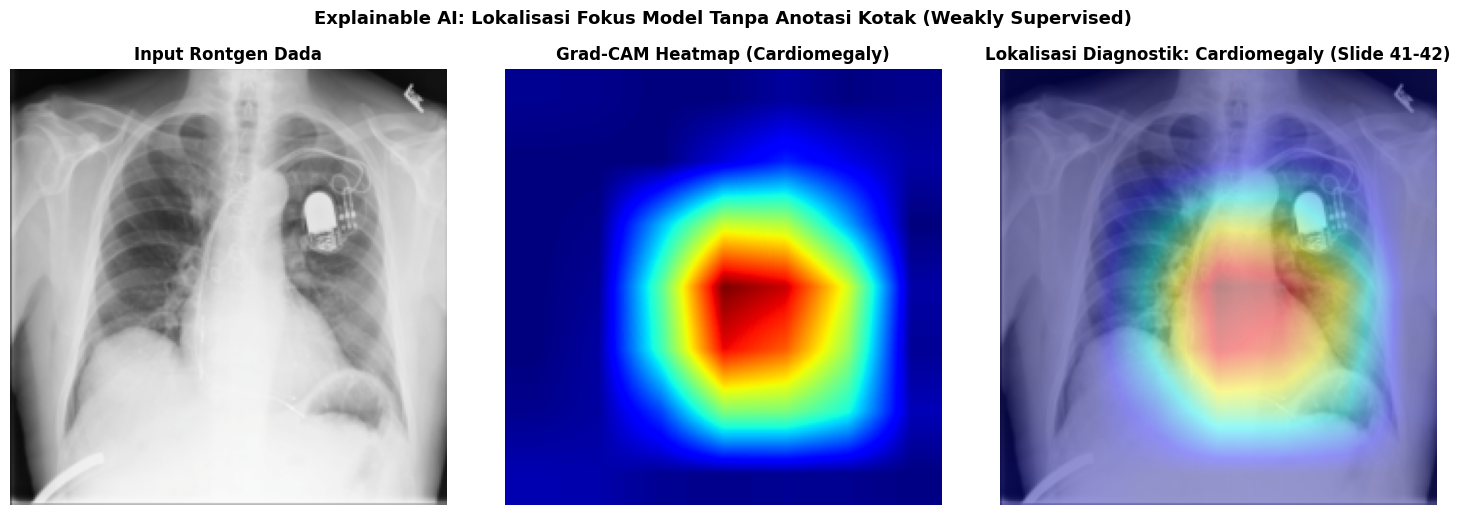

In [13]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[0, target_class]
        score.backward()

        # Pooling gradien
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations[0]

        for i in range(len(pooled_gradients)):
            activations[i, :, :] *= pooled_gradients[i]

        heatmap = torch.mean(activations, dim=0).squeeze().cpu().detach().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap /= (np.max(heatmap) + 1e-8)
        return heatmap

# Inisialisasi GradCAM pada layer denseblock4 DenseNet-121
target_layer = model.features.denseblock4
grad_cam = GradCAM(model, target_layer)

# Pilih penyakit dengan probabilitas tertinggi untuk dilokalisasi
target_idx = np.argmax(probs)
target_disease_name = DISEASE_LABELS[target_idx]

# Buat heatmap
heatmap = grad_cam.generate_heatmap(input_tensor, target_class=target_idx)
heatmap_resized = cv2.resize(heatmap, (224, 224))
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0

# Overlay dengan gambar rontgen asli
overlay = 0.6 * disp_img + 0.4 * heatmap_color
overlay = np.clip(overlay, 0, 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
ax1.imshow(disp_img, cmap='gray')
ax1.set_title("Input Rontgen Dada", fontweight='bold')
ax1.axis('off')

ax2.imshow(heatmap_resized, cmap='jet')
ax2.set_title(f"Grad-CAM Heatmap ({target_disease_name})", fontweight='bold')
ax2.axis('off')

ax3.imshow(overlay)
ax3.set_title(f"Lokalisasi Diagnostik: {target_disease_name}", fontweight='bold')
ax3.axis('off')

plt.suptitle("Explainable AI: Lokalisasi Fokus Model Tanpa Anotasi Kotak (Weakly Supervised)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

14 penyakit akan ditampilkan lengkap beserta persentase probabilitasnya (dari yang tertinggi hingga terendah).

In [14]:
!pip install -q gradio

import gradio as gr
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

# 1. Pastikan model dalam mode evaluasi
model.eval()

# 2. Fungsi inferensi: CLAHE + Prediksi 14 Patologi + Grad-CAM
def predict_and_visualize(input_pil):
    if input_pil is None:
        return None, None, "Silakan unggah citra rontgen dada terlebih dahulu."

    # A. Apply CLAHE for contrast enhancement in the demo UI
    # Note: training used standard normalized radiographs; harmonizing CLAHE in training is planned to remove train-inference skew.
    img_gray = np.array(input_pil.convert('L'))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_clahe = clahe.apply(img_gray)
    img_clahe_pil = Image.fromarray(img_clahe).convert('RGB')

    # B. Transformasi Tensor
    transform_pipeline = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    input_tensor = transform_pipeline(img_clahe_pil).unsqueeze(0).to(device)

    # C. Grad-CAM Setup pada layer terakhir DenseNet
    target_layer = model.features.denseblock4
    activations, gradients = [], []

    def fwd_hook(module, inp, out):
        activations.append(out)
    def bwd_hook(module, gin, gout):
        gradients.append(gout[0])

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    # D. Forward Pass
    model.zero_grad()
    logits = model(input_tensor)
    probs = torch.sigmoid(logits).squeeze().cpu().detach().numpy()

    # E. Backward Pass untuk penyakit dengan probabilitas tertinggi
    top_idx = int(np.argmax(probs))
    top_disease = DISEASE_LABELS[top_idx]
    top_score = float(probs[top_idx])

    logits[0, top_idx].backward()

    # Hitung Grad-CAM
    grads = gradients[0].cpu().data.numpy()[0]
    acts = activations[0].cpu().data.numpy()[0]
    weights = np.mean(grads, axis=(1, 2))
    cam = np.zeros(acts.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * acts[i]

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # Lepas hook agar memori bersih
    h1.remove()
    h2.remove()

    # F. Overlay Heatmap ke citra rontgen
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    base_img_resized = np.array(img_clahe_pil.resize((224, 224)))
    overlay = cv2.addWeighted(base_img_resized, 0.6, heatmap_colored, 0.4, 0)

    # G. Format Probabilitas Lengkap 14 Penyakit
    prob_dict = {DISEASE_LABELS[i]: float(probs[i]) for i in range(len(DISEASE_LABELS))}

    # Ringkasan Temuan Klinis
    findings = [f"**{DISEASE_LABELS[i]}** ({probs[i]*100:.1f}%)" for i in range(len(DISEASE_LABELS)) if probs[i] >= 0.5]
    if findings:
        report_text = f"### ⚠️ Temuan Aktif Positif (Threshold ≥ 50%):\n- " + "\n- ".join(findings)
    else:
        report_text = f"### ✅ Tidak Ada Patologi di Atas Threshold (No Finding)\n*Kemungkinan tertinggi: {top_disease} ({top_score*100:.1f}%)*"

    return prob_dict, overlay, report_text

# Ambil sampel dari dataset validasi untuk tombol contoh
sample_examples = [[val_df['image_path'].iloc[i]] for i in range(min(4, len(val_df)))]

# 3. Antarmuka Web Interaktif
with gr.Blocks(theme=gr.themes.Soft(), title="ThoraxAI Clinical Engine") as demo:
    gr.Markdown("# 🫁 ThoraxAI: Deep Learning Multi-Label Diagnostic Engine")
    gr.Markdown("Sistem Diagnosis Rontgen Dada Otomatis untuk **14 Patologi Paru & Jantung** berbasis **DenseNet-121**, **CLAHE**, dan **Grad-CAM**.")

    with gr.Row():
        with gr.Column(scale=1):
            input_image = gr.Image(type="pil", label="Unggah Citra Rontgen Toraks")
            btn_diagnose = gr.Button("🔍 Jalankan Diagnosis Lengkap", variant="primary")
            gr.Examples(examples=sample_examples, inputs=input_image, label="Pilihan Sampel Pengujian")

        with gr.Column(scale=1):
            cam_output = gr.Image(label="Grad-CAM Explainable AI (Area Lesi Patologi Dominan)")
            report_output = gr.Markdown(label="Status Diagnosis Klinis")
            # Menampilkan seluruh 14 patologi
            label_output = gr.Label(num_top_classes=14, label="Probabilitas Lengkap Seluruh 14 Patologi Paru")

    btn_diagnose.click(
        fn=predict_and_visualize,
        inputs=input_image,
        outputs=[label_output, cam_output, report_output]
    )

# Jalankan server
demo.launch(share=True, debug=False)

CELL A: Galeri Perbandingan Karakteristik Antar-Patologi

Kegunaan: Menampilkan sampel rontgen representatif untuk membedakan bentuk visual tiap patologi (misal: Cardiomegaly di area siluet jantung tengah vs Effusion di sudut bawah diafragma vs Nodule berupa titik putih bulat).

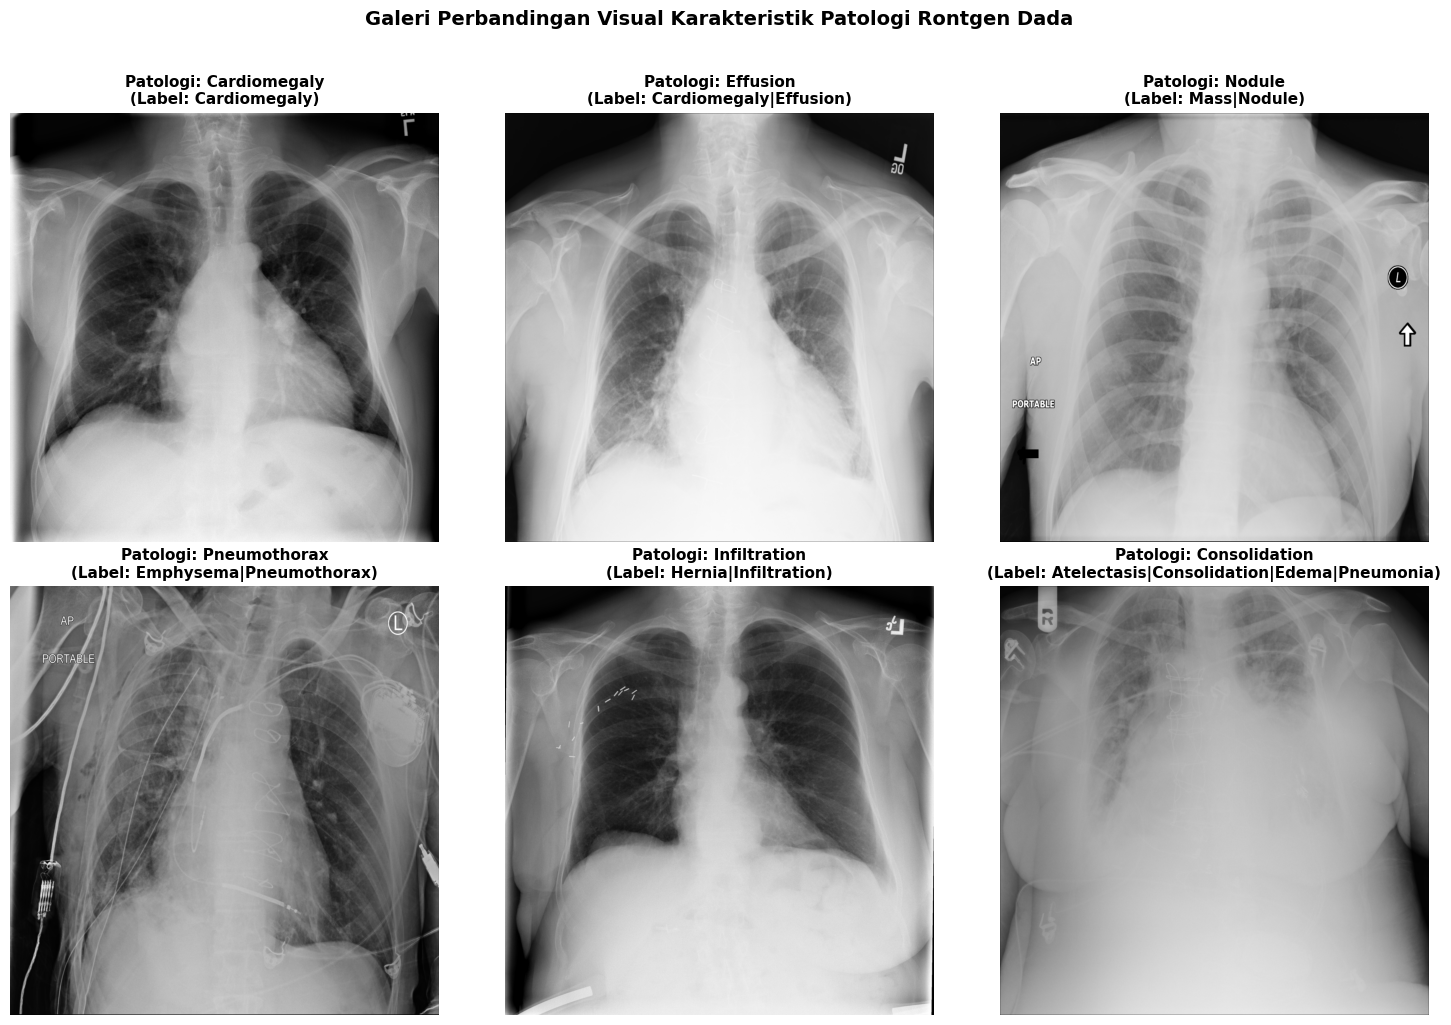

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

# Pilih 6 patologi utama dengan karakteristik visual kontras
target_diseases = ['Cardiomegaly', 'Effusion', 'Nodule', 'Pneumothorax', 'Infiltration', 'Consolidation']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, disease in zip(axes.flat, target_diseases):
    # Cari 1 gambar yang memiliki penyakit ini (dan sebisa mungkin hanya penyakit ini)
    sample_row = df[df[disease] == 1].iloc[0]
    img = Image.open(sample_row['image_path']).convert('RGB')

    ax.imshow(img, cmap='gray')
    ax.set_title(f"Patologi: {disease}\n(Label: {sample_row['Finding Labels']})", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle("Galeri Perbandingan Visual Karakteristik Patologi Rontgen Dada", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

CELL B: Visualisasi Uji Berbagai Resolusi pada 1 Patologi Pilihan (Contoh: Nodule)

Kegunaan: Menampilkan 1 foto rontgen pasien yang sama yang diubah ke 4 resolusi berbeda ( 112×112, 112×112, 224×224, 224×224, 384×384, 384×384, dan 512×512, 512×512), lengkap dengan kotak zoom-in area lesi. Ini memperlihatkan di mana detail mulai rusak/kabur jika resolusi terlalu kecil.

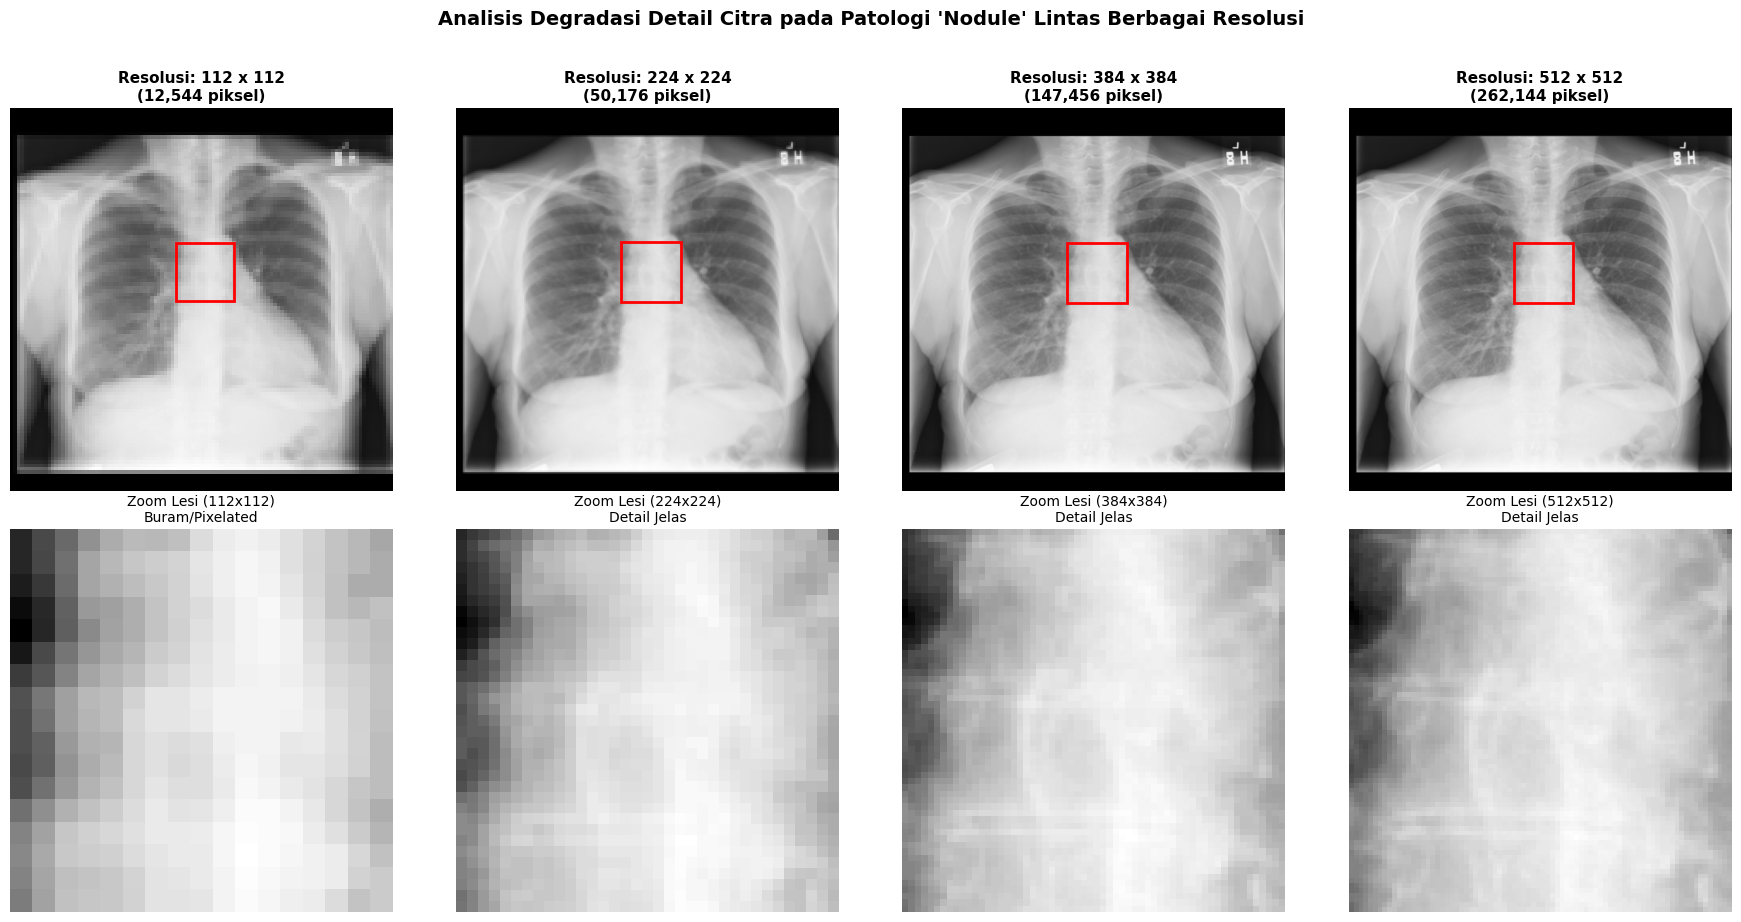

In [16]:
# 1. Pilih 1 patologi fokus (bisa diganti: 'Nodule', 'Cardiomegaly', 'Pneumothorax')
TARGET_PATOLOGY = 'Nodule'

# Cari pasien dengan patologi tersebut
nodule_sample = df[df[TARGET_PATOLOGY] == 1].iloc[1]['image_path']
orig_img = Image.open(nodule_sample).convert('L')

# 4 Variasi Resolusi Uji
resolutions = [112, 224, 384, 512]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for idx, res in enumerate(resolutions):
    # Resize ke resolusi uji
    resized = orig_img.resize((res, res), Image.BILINEAR)
    img_np = np.array(resized)

    # Baris 1: Full Chest X-Ray
    axes[0, idx].imshow(img_np, cmap='gray')
    axes[0, idx].set_title(f"Resolusi: {res} x {res}\n({res*res:,} piksel)", fontsize=11, fontweight='bold')

    # Beri kotak merah di area crop fokus (sesuai skala resolusi)
    scale = res / 512.0
    x, y, w, h = int(220 * scale), int(180 * scale), int(80 * scale), int(80 * scale)
    rect = plt.Rectangle((x, y), w, h, edgecolor='red', facecolor='none', linewidth=2)
    axes[0, idx].add_patch(rect)
    axes[0, idx].axis('off')

    # Baris 2: Zoom-in Area Lesi
    crop_patch = img_np[y:y+h, x:x+w]
    axes[1, idx].imshow(crop_patch, cmap='gray')
    axes[1, idx].set_title(f"Zoom Lesi ({res}x{res})\n{'Buram/Pixelated' if res <= 112 else 'Detail Jelas'}", fontsize=10)
    axes[1, idx].axis('off')

plt.suptitle(f"Analisis Degradasi Detail Citra pada Patologi '{TARGET_PATOLOGY}' Lintas Berbagai Resolusi",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

CELL C: Benchmark & Grafik Penentuan "Resolusi Paling Optimal"

Kegunaan: Menjalankan inferensi pada data validasi khusus patologi tersebut di setiap resolusi, mengukur:

Skor Performa (ROC-AUC)
Kecepatan Komputasi (Milidetik per Gambar)
Konsumsi Memori GPU

Dari grafik ini, kamu bisa menyimpulkan resolusi mana yang menjadi titik sweet spot (titik optimal: akurasi tertinggi dengan biaya komputasi yang efisien).

=== BENCHMARK RESOLUSI UNTUK PATOLOGI: Nodule ===
Resolusi 112x112 | ROC-AUC: 0.6315 | Waktu Inferensi: 20.26 ms/gambar
Resolusi 224x224 | ROC-AUC: 0.6686 | Waktu Inferensi: 21.28 ms/gambar
Resolusi 384x384 | ROC-AUC: 0.6370 | Waktu Inferensi: 24.75 ms/gambar
Resolusi 512x512 | ROC-AUC: 0.6315 | Waktu Inferensi: 28.86 ms/gambar


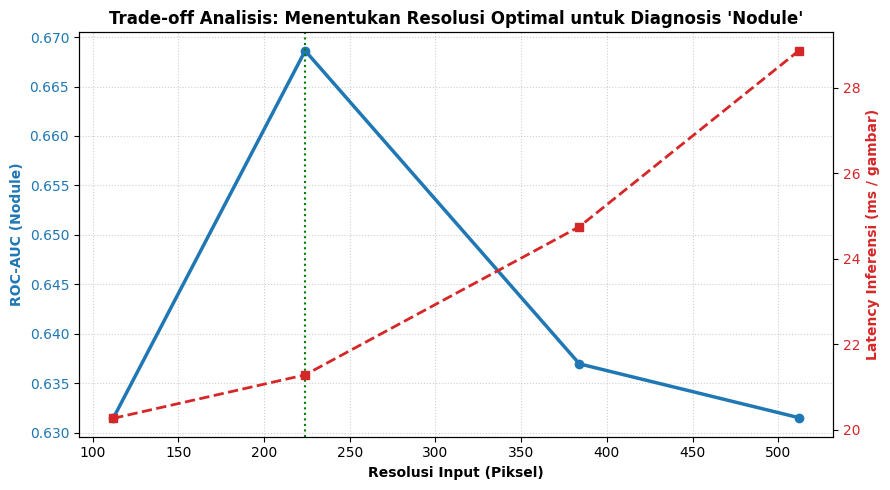


Kesimpulan: Resolusi paling optimal untuk deteksi 'Nodule' adalah 224x224.


In [17]:
import time

resolutions = [112, 224, 384, 512]
auc_results = []
inference_times = []

# Filter data validasi yang memiliki patologi target vs kontrol
target_col_idx = DISEASE_LABELS.index(TARGET_PATOLOGY)
val_subset = val_df.sample(min(500, len(val_df)), random_state=42).reset_index(drop=True)

print(f"=== BENCHMARK RESOLUSI UNTUK PATOLOGI: {TARGET_PATOLOGY} ===")

for res in resolutions:
    eval_transform = transforms.Compose([
        transforms.Resize((res, res)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Evaluasi subset
    test_ds = ChestXrayDataset(val_subset, transform=eval_transform)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

    all_p, all_t = [], []
    t_start = time.time()

    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs = imgs.to(device)
            # Jika arsitektur DenseNet bawaan menerima ukuran berapa saja (karena AdaptiveAvgPool2d)
            outs = model(imgs)
            probs = torch.sigmoid(outs)[:, target_col_idx].cpu().numpy()
            all_p.extend(probs)
            all_t.extend(lbls[:, target_col_idx].numpy())

    elapsed = (time.time() - t_start) / len(val_subset) * 1000 # ms per image
    auc = roc_auc_score(all_t, all_p)

    auc_results.append(auc)
    inference_times.append(elapsed)
    print(f"Resolusi {res}x{res} | ROC-AUC: {auc:.4f} | Waktu Inferensi: {elapsed:.2f} ms/gambar")

# --- PLOT PENENTUAN RESOLUSI PALING OPTIMAL ---
fig, ax1 = plt.subplots(figsize=(9, 5))

color = 'tab:blue'
ax1.set_xlabel('Resolusi Input (Piksel)', fontweight='bold')
ax1.set_ylabel(f'ROC-AUC ({TARGET_PATOLOGY})', color=color, fontweight='bold')
line1 = ax1.plot(resolutions, auc_results, marker='o', linewidth=2.5, color=color, label='ROC-AUC Score')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle=':', alpha=0.6)

# Sumbu kedua untuk Waktu Komputasi
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Latency Inferensi (ms / gambar)', color=color, fontweight='bold')
line2 = ax2.plot(resolutions, inference_times, marker='s', linestyle='--', linewidth=2, color=color, label='Inference Latency')
ax2.tick_params(axis='y', labelcolor=color)

# Sorot titik optimal (Sweet Spot)
optimal_idx = np.argmax(auc_results)
optimal_res = resolutions[optimal_idx]
ax1.axvline(optimal_res, color='green', linestyle=':', label=f'Optimal ({optimal_res}x{optimal_res})')

plt.title(f"Trade-off Analisis: Menentukan Resolusi Optimal untuk Diagnosis '{TARGET_PATOLOGY}'", fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

print(f"\nKesimpulan: Resolusi paling optimal untuk deteksi '{TARGET_PATOLOGY}' adalah {optimal_res}x{optimal_res}.")